In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [5]:
print(df.isna().sum())

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [6]:
categorical = df.select_dtypes(include=['object', 'string']).columns.tolist()
numerical = df.select_dtypes(exclude=['object', 'string']).columns.tolist()

In [7]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [9]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [10]:
df_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4740,paid_ads,technology,employed,asia,80198.0,5,9,0.91,1
1452,paid_ads,retail,employed,asia,50548.0,2,5,0.48,0
2846,NA,finance,employed,NA,76300.0,0,3,0.42,0
4670,paid_ads,finance,employed,NA,80371.0,2,6,0.49,0
168,organic_search,finance,employed,asia,73567.0,2,4,0.48,1
...,...,...,...,...,...,...,...,...,...
253,paid_ads,finance,employed,north_america,84573.0,2,3,0.37,1
1366,events,technology,employed,asia,85051.0,1,3,0.56,0
753,events,retail,unemployed,asia,21561.0,0,1,0.17,0
4990,organic_search,healthcare,unemployed,south_america,31691.0,3,5,0.49,1


In [11]:
df_val

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
913,social_media,technology,student,south_america,0.0,1,1,0.26,0
1288,paid_ads,education,employed,north_america,63357.0,4,7,0.73,1
3551,social_media,healthcare,employed,north_america,72351.0,2,3,0.33,1
2532,organic_search,technology,student,south_america,41501.0,2,2,0.41,1
2678,organic_search,education,employed,NA,44817.0,3,7,0.73,0
...,...,...,...,...,...,...,...,...,...
924,social_media,healthcare,employed,africa,59325.0,3,6,0.71,1
3282,social_media,retail,employed,NA,54394.0,1,5,0.46,1
2067,social_media,healthcare,employed,south_america,51328.0,3,6,0.58,1
4332,organic_search,retail,unemployed,africa,13315.0,3,5,0.51,1


In [12]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NA,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [13]:
df_test

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
2764,organic_search,healthcare,student,south_america,20241.0,1,3,0.42,0
4767,organic_search,manufacturing,self_employed,asia,45817.0,2,3,0.41,0
3814,organic_search,healthcare,employed,north_america,82802.0,3,7,0.69,1
3499,paid_ads,technology,unemployed,europe,61015.0,1,2,0.19,0
2735,referral,retail,unemployed,north_america,15154.0,2,2,0.39,0
...,...,...,...,...,...,...,...,...,...
448,paid_ads,NA,employed,north_america,79186.0,3,5,0.50,1
921,NA,education,self_employed,north_america,34582.0,3,7,0.65,1
4087,social_media,healthcare,unemployed,europe,39573.0,2,1,0.25,0
1242,referral,technology,employed,north_america,100953.0,2,7,0.70,1


In [14]:
from sklearn.metrics import roc_auc_score

In [18]:
numerical_features = ['lead_score', 'number_of_courses_viewed','interaction_count', 'annual_income']

In [20]:
y_train = df_train.converted.values

In [22]:
for c in numerical_features:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(c, round(auc, 4))

lead_score 0.7882
number_of_courses_viewed 0.723
interaction_count 0.7649
annual_income 0.6082


In [23]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [36]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

In [37]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [38]:
y_pred = model.predict_proba(X_val)[:, 1]
print(round(roc_auc_score(y_val, y_pred), 3))

0.732


In [39]:
import numpy as np
import matplotlib.pyplot as plt

In [40]:
rows = []

In [41]:
for t in np.arange(0.0, 1.01, 0.01):
    pred = y_pred >= t

    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    rows.append((round(t, 2), precision, recall))

In [42]:
scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall'])

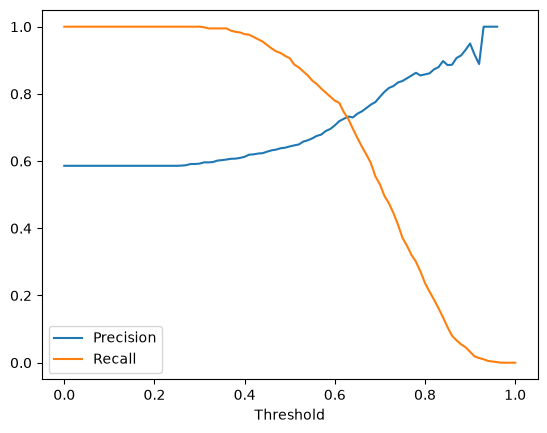

In [45]:
plt.plot(scores.threshold, scores.precision, label='Precision')
plt.plot(scores.threshold, scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.show()

In [48]:
rows = []
for t in np.arange(0.0, 1.0, 0.01):
    pred = y_pred >= t

    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0

    rows.append((round(t, 2), p, r, f1))

In [50]:
scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])
print(scores.loc[scores.f1.idxmax()]) 

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64


In [51]:
from sklearn.model_selection import KFold

In [52]:
from sklearn.metrics import roc_auc_score

In [53]:
def train(df_train, y_train):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train.to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, model

In [55]:
def predict(df, dv, model):
    X = dv.transform(df.to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [56]:
df_full_train = df_full_train.reset_index(drop=True)

In [57]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [58]:
scores = []

In [69]:
for fold, (train_idx, val_idx) in enumerate(kfold.split(df_full_train), start=1):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_va = df_va.converted.values
    df_tr = df_tr.drop(columns='converted')
    df_va = df_va.drop(columns='converted')

    dv, model = train(df_tr, y_tr)
    y_pred = predict(df_va, dv, model)
    auc = roc_auc_score(y_va, y_pred)
    scores.append(auc)

print(f"Fold {fold}: AUC = {auc:.4f}")
print(np.mean(scores))
print(round(np.std(scores), 3))

Fold 1: AUC = 0.7306
Fold 2: AUC = 0.7296
Fold 3: AUC = 0.7363
Fold 4: AUC = 0.7412
Fold 5: AUC = 0.7209
0.7317269710972524
0.007


In [70]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [71]:
for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx] #training
        df_va = df_full_train.iloc[val_idx] #validation

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values
        df_tr = df_tr.drop(columns='converted')
        df_va = df_va.drop(columns='converted')

        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(df_tr.to_dict(orient='records'))
        X_va = dv.transform(df_va.to_dict(orient='records'))

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_tr, y_tr)

        y_pred = model.predict_proba(X_va)[:, 1]
        scores.append(roc_auc_score(y_va, y_pred))

    print(f"C={C}: mean={np.mean(scores):.3f}, std={np.std(scores):.3f}")

C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.010
C=1: mean=0.732, std=0.007


In [ ]:
#75%